# 자연어 처리 4일차 (1) — 행렬 곱 · RNN 셀 한 칸씩 · tanh · BPTT

교재 `자연어처리` 교재v1 **p.69~78** (학습 단계 · 순환 신경망 RNN · 순차 데이터 · 기본 원리 · 모델 구성 · 연산 과정 · tanh · BPTT) 와 수업 자료 **「행렬 간의 곱셈」** 을 직접 계산하며 확인한 노트입니다.

- 같은 구조로 IMDB 영화 리뷰 감성 분석을 끝까지 학습한 것(필기 `nlp_실습07`)은 [`imdb_rnn_sentiment.ipynb`](./imdb_rnn_sentiment.ipynb) 에 있습니다.
- 교재 · 필기에서 고친 부분은 **📝 고친 부분** 으로 적었습니다. **애니메이션(GIF)** 은 [`images/`](./images/) 폴더에 있습니다.

$$h_t = \tanh(W_h\,h_{t-1} + W_x\,x_t + b)$$

| 기호 | 뜻 | 오늘 모델의 크기 |
|---|---|---|
| $x_t$ | t 번째 단어의 임베딩 벡터 | (1, 32) |
| $h_{t-1}$ | 바로 앞까지 읽은 내용(은닉 상태) | (1, 16) |
| $W_x$ · $W_h$ · $b$ | 학습되는 가중치 — **모든 시점이 같은 것을 공유** | (32, 16) · (16, 16) · (16,) |

## 0. 설치 · 실행 방법

| 패키지 | 이 노트에서 쓰는 것 | 설치 |
|---|---|---|
| `numpy` | 행렬 곱 · RNN 셀 손계산 | Colab 기본 포함 |
| `torch` | `nn.RNN` 과 손계산 비교 · 기울기(BPTT) 계산 | Colab 기본 포함 · 로컬은 `pip install torch` |
| `matplotlib` | tanh · 기울기 그래프 | Colab 기본 포함 |

**실행 순서** : 맨 위부터 **[런타임] → [모두 실행]**. 데이터 다운로드 · GPU 없이 CPU 로 몇 초면 끝난다.

In [1]:
# ① 설치 (로컬에서 처음 한 번 — Colab 은 기본 포함)
# !pip install -q numpy torch matplotlib

In [2]:
# 그래프 한글 폰트 설정 (운영체제별)
import platform
import matplotlib.pyplot as plt

if platform.system() == 'Windows':
    plt.rcParams['font.family'] = 'Malgun Gothic'
elif platform.system() == 'Darwin':
    plt.rcParams['font.family'] = 'AppleGothic'
# Colab(리눅스) : !apt-get install -y fonts-nanum 후 런타임 재시작 → plt.rcParams['font.family'] = 'NanumGothic'
plt.rcParams['axes.unicode_minus'] = False

In [3]:
import numpy as np
import torch
import torch.nn as nn
np.set_printoptions(precision=4, suppress=True)

## 1. 행렬 간의 곱셈 (수업 자료 「행렬 간의 곱셈」)

**앞 행렬은 행(가로)**, **뒤 행렬은 열(세로)** 을 잡아 같은 자리끼리 곱해 더한다 → 결과의 (i, j) 칸.

In [4]:
A_ = np.array([[1, 0],
               [2, 3]])
B_ = np.array([[2, 1],
               [3, 1]])

# 칸 하나씩 손으로 : (i 행) · (j 열)
C = np.zeros((2, 2), dtype=int)
for i in range(2):
    for j in range(2):
        C[i, j] = sum(A_[i, k] * B_[k, j] for k in range(2))
        print(f'C[{i},{j}] = ' + ' + '.join(f'({A_[i, k]}×{B_[k, j]})' for k in range(2)) + f' = {C[i, j]}')

print('\n손계산 :\n', C)
print('np.matmul :\n', np.matmul(A_, B_))
print('@ 연산자 :\n', A_ @ B_)
print('\n순서를 바꾸면 B @ A :\n', B_ @ A_, '  ← 행렬 곱은 교환법칙이 성립하지 않는다')

C[0,0] = (1×2) + (0×3) = 2
C[0,1] = (1×1) + (0×1) = 1
C[1,0] = (2×2) + (3×3) = 13
C[1,1] = (2×1) + (3×1) = 5

손계산 :
 [[ 2  1]
 [13  5]]
np.matmul :
 [[ 2  1]
 [13  5]]
@ 연산자 :
 [[ 2  1]
 [13  5]]

순서를 바꾸면 B @ A :
 [[4 3]
 [5 3]]   ← 행렬 곱은 교환법칙이 성립하지 않는다


In [5]:
# 필기 cell 15 예제 : (2,3) × (3,2) = (2,2)
m1 = np.array([[1, 2, 3], [4, 5, 6]])
m2 = np.array([[1, 2], [3, 4], [5, 6]])
print(m1 @ m2)

# 일반화 (m, k) × (k, n) = (m, n) — 가운데 k 가 같아야 한다
print('(10,20) × (20,5) →', (np.ones((10, 20)) @ np.ones((20, 5))).shape)

# 필기에서 만들다 만 '모양이 맞지 않을 때 에러' 예시
m3 = np.array([[1, 2], [3, 4]])                  # (2, 2)
try:
    m1 @ m3                                      # (2,3) × (2,2) → 가운데 3 ≠ 2
except ValueError as e:
    print('에러 :', e)

# 원소끼리 곱(*)과 행렬 곱(@)은 다르다
print('원소별 곱 A*B :\n', A_ * B_)

[[22 28]
 [49 64]]
(10,20) × (20,5) → (10, 5)
에러 : matmul: Input operand 1 has a mismatch in its core dimension 0, with gufunc signature (n?,k),(k,m?)->(n?,m?) (size 2 is different from 3)
원소별 곱 A*B :
 [[2 0]
 [6 3]]


> **📝 고친 부분 (필기 cell 15~16)** 에러 예시는 `matrix3` 를 만들고 끝나 실제 에러를 보여 주지 않았다 → `try / except` 로 메시지 확인. 주석 '트렌스포머' → **트랜스포머**.

## 2. 순차 데이터 — 순서가 바뀌면 뜻이 바뀐다 (교재 p.70)

In [6]:
from collections import Counter
a, b = '도시', '시도'
print('글자 빈도 (BoW 방식) 같음? :', Counter(a) == Counter(b))
print('순서까지 보면 같음?         :', list(a) == list(b))

s1, s2 = 'not good , bad', 'not bad , good'
print('\n단어 빈도 같음? :', Counter(s1.split()) == Counter(s2.split()), '— 하지만 뜻은 반대')

글자 빈도 (BoW 방식) 같음? : True
순서까지 보면 같음?         : False

단어 빈도 같음? : True — 하지만 뜻은 반대


- 글자 단위로 세면 `도시` 와 `시도` 가 같고, 단어 단위로 세면 `not good , bad` 와 `not bad , good` 이 같다 — 어제 만든 BoW(`CountVectorizer`)는 **세는 단위 안의 순서를 버린다**. (단어 단위 BoW 에서 `도시` · `시도` 는 서로 다른 단어라 구별된다)
- RNN 은 단어를 **순서대로** 하나씩 읽으며 앞 내용을 은닉 상태 $h$ 에 담아 넘긴다.

## 3. RNN 셀 한 칸씩 — 손계산 vs `nn.RNN` (교재 p.75~76)

In [7]:
torch.manual_seed(0)
rnn = nn.RNN(input_size=32, hidden_size=16, batch_first=True)   # 오늘 IMDB 모델과 같은 크기

for name, p in rnn.named_parameters():
    print(f'{name:14s} {tuple(p.shape)}')

weight_ih_l0   (16, 32)
weight_hh_l0   (16, 16)
bias_ih_l0     (16,)
bias_hh_l0     (16,)


PyTorch 는 가중치를 **(출력, 입력)** 모양으로 저장한다 → 교재 그림의 $W_x$ (32, 16) = `weight_ih_l0.T`, $W_h$ (16, 16) = `weight_hh_l0.T`. 편향은 두 개(`bias_ih` + `bias_hh`)를 더해서 쓴다 — 교재의 $b$ 하나와 같은 역할.

In [8]:
T = 5                                            # 단어 5개짜리 문장
x = torch.randn(1, T, 32)                        # (배치 1, 시점 5, 임베딩 32)

Wx = rnn.weight_ih_l0.detach().T.numpy()         # (32, 16)
Wh = rnn.weight_hh_l0.detach().T.numpy()         # (16, 16)
b = (rnn.bias_ih_l0 + rnn.bias_hh_l0).detach().numpy()

h = np.zeros((1, 16))                            # h_0 = 0 (처음엔 기억 없음)
hs = []
for t in range(T):
    xt = x[0, t:t + 1].numpy()                   # (1, 32)
    h = np.tanh(h @ Wh + xt @ Wx + b)            # (1,16)@(16,16) + (1,32)@(32,16) → (1,16)
    hs.append(h)
    print(f't={t + 1}  h_t 앞 4칸 : {h[0, :4]}')

output, h_n = rnn(x)
print('\n손계산 == nn.RNN ?', np.allclose(np.vstack(hs), output[0].detach().numpy(), atol=1e-6))

t=1  h_t 앞 4칸 : [-0.6139 -0.6756  0.2709  0.1971]
t=2  h_t 앞 4칸 : [ 0.2439  0.7258 -0.7256  0.4019]
t=3  h_t 앞 4칸 : [-0.1481  0.0178 -0.174   0.7807]
t=4  h_t 앞 4칸 : [ 0.065  -0.6413  0.3967 -0.4384]
t=5  h_t 앞 4칸 : [-0.5915 -0.9214  0.2465  0.5122]

손계산 == nn.RNN ? True


In [9]:
print('output 모양 :', tuple(output.shape), '→ (배치, 시점, 16) : 모든 시점의 은닉 상태 h_1 … h_T')
print('h_n 모양    :', tuple(h_n.shape), '   → (층 수, 배치, 16) : 맨 마지막 h_T 하나')
print('output[:, -1] == h_n[0] ?', torch.allclose(output[:, -1], h_n[0]))

output 모양 : (1, 5, 16) → (배치, 시점, 16) : 모든 시점의 은닉 상태 h_1 … h_T
h_n 모양    : (1, 1, 16)    → (층 수, 배치, 16) : 맨 마지막 h_T 하나
output[:, -1] == h_n[0] ? True


> **📝 고친 부분 (교재 p.76 그림)** `h_470 → [모든 시점의 은닉 상태]` 처럼 `h_470` 하나에 두 설명이 붙어 있다 → **모든 시점**은 `output`(h_1 … h_470, 모양 (배치, 470, 16)), **마지막 시점**은 `h_n`(= h_470 만, (1, 배치, 16)). 감성 분류는 마지막 `h_n` 을 Linear 층에 넣는다.

## 4. 가중치 개수 — 길이 470 과 상관없다 (교재 p.74)

In [10]:
emb = nn.Embedding(10000, 32)
fc = nn.Linear(16, 1)
for name, layer in [('Embedding(10000, 32)', emb), ('RNN(32 → 16)', rnn), ('Linear(16 → 1)', fc)]:
    print(f'{name:22s} 가중치 {sum(p.numel() for p in layer.parameters()):>8,}개')

review = torch.randint(1, 10000, (1, 470))           # 리뷰 1개 = 단어 번호 470개
print('\n리뷰 1개 → Embedding 결과 :', tuple(emb(review).shape), '← (470, 32) 는 이 **입력 행렬**')
print('리뷰 길이를 100 으로 바꿔도 RNN 가중치 :', sum(p.numel() for p in rnn.parameters()), '개 그대로')

Embedding(10000, 32)   가중치  320,000개
RNN(32 → 16)           가중치      800개
Linear(16 → 1)         가중치       17개

리뷰 1개 → Embedding 결과 : (1, 470, 32) ← (470, 32) 는 이 **입력 행렬**
리뷰 길이를 100 으로 바꿔도 RNN 가중치 : 800 개 그대로


> **📝 고친 부분 (교재 p.74)** RNN layer 아래 '**가중치 행렬 (470, 32)**' → (470, 32) 는 리뷰 1개를 임베딩한 **입력 행렬**이다. RNN 의 가중치는 $W_x$ (32, 16) · $W_h$ (16, 16) · 편향 16 + 16 = **800개**뿐이고, 470 개 시점이 **같은 가중치를 돌려 쓴다**(그래서 '순환'). 길이가 바뀌어도 가중치 수는 같다.

## 5. 활성화 함수 tanh (교재 p.77)

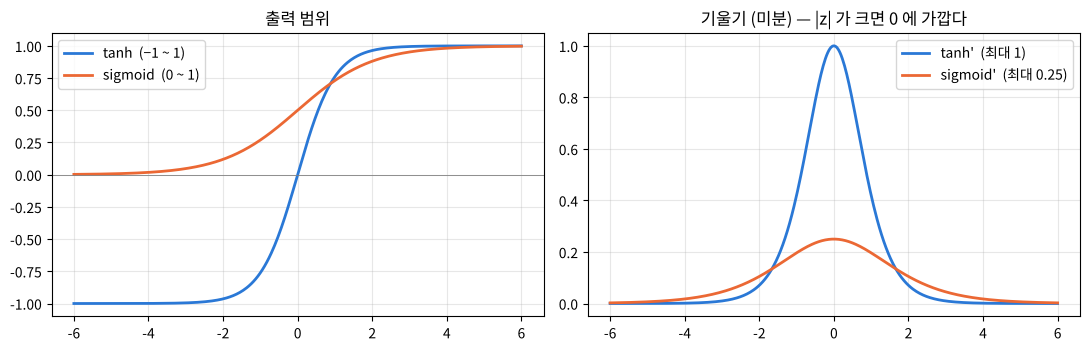

tanh(z) == 2·sigmoid(2z) − 1 ? True


In [11]:
import matplotlib.pyplot as plt
z = np.linspace(-6, 6, 400)
sig = 1 / (1 + np.exp(-z))
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
axes[0].plot(z, np.tanh(z), label='tanh  (−1 ~ 1)', color='#2a78d6', lw=2)
axes[0].plot(z, sig, label='sigmoid  (0 ~ 1)', color='#eb6834', lw=2)
axes[0].axhline(0, color='gray', lw=0.6); axes[0].legend(); axes[0].set_title('출력 범위'); axes[0].grid(alpha=0.3)
axes[1].plot(z, 1 - np.tanh(z) ** 2, label="tanh'  (최대 1)", color='#2a78d6', lw=2)
axes[1].plot(z, sig * (1 - sig), label="sigmoid'  (최대 0.25)", color='#eb6834', lw=2)
axes[1].legend(); axes[1].set_title('기울기 (미분) — |z| 가 크면 0 에 가깝다'); axes[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()
print('tanh(z) == 2·sigmoid(2z) − 1 ?', np.allclose(np.tanh(z), 2 / (1 + np.exp(-2 * z)) - 1))

- tanh 는 sigmoid 를 **세로로 2배 늘리고 아래로 내린 것**(`tanh(z) = 2σ(2z) − 1`) — 0 을 중심으로 −1 ~ 1. 은닉 상태가 한쪽으로 쏠리지 않는다.
- 기울기는 최대 1 이고 |z| 가 크면 0 에 가깝다 → 이것을 470번 곱하면 아래 BPTT 의 **기울기 소실**.

> **📝 고친 부분 (교재 p.77)** `하이퍼블릭 탄젠트` → **하이퍼볼릭**(hyperbolic) 탄젠트.

## 6. BPTT — 마지막 오차를 과거로 거꾸로 (교재 p.78)

마지막 시점의 손실에서 각 시점 은닉 상태 $h_t$ 까지 기울기가 얼마나 도달하는지 직접 잰다.

t = 100   기울기 크기 5.99e-01
t =  99   기울기 크기 2.44e-01
t =  95   기울기 크기 5.56e-03
t =  90   기울기 크기 9.52e-05
t =  80   기울기 크기 6.49e-09
t =  50   기울기 크기 2.81e-21
t =   1   기울기 크기 0.00e+00


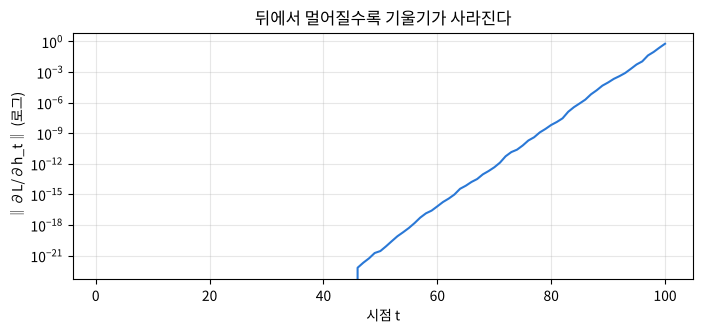

In [12]:
torch.manual_seed(0)
T = 100
x = torch.randn(1, T, 32)
h = torch.zeros(1, 1, 16)
hs = []
for t in range(T):                                 # 한 시점씩 펼쳐서(unroll) 실행 — nn.RNN 한 번과 같은 계산
    _, h = rnn(x[:, t:t + 1], h)
    h.retain_grad()                                # 각 시점 h_t 의 기울기를 남겨 두기
    hs.append(h)
loss = fc(h[0]).sum()                              # 마지막 h_T 로만 예측 → 손실
loss.backward()                                    # BPTT : t = T → 1 방향으로 연쇄 법칙

g = np.array([hh.grad.norm().item() for hh in hs]) # ‖∂L/∂h_t‖
for t in [T, T - 1, T - 5, T - 10, T - 20, T - 50, 1]:
    print(f't = {t:3d}   기울기 크기 {g[t - 1]:.2e}')

plt.figure(figsize=(8, 3.2))
plt.semilogy(range(1, T + 1), g, color='#2a78d6')
plt.xlabel('시점 t'); plt.ylabel('‖∂L/∂h_t‖ (로그)'); plt.title('뒤에서 멀어질수록 기울기가 사라진다'); plt.grid(alpha=0.3)
plt.show()

In [13]:
# 가중치 W_x 의 기울기는 470개(여기선 100개) 시점의 기울기를 모두 더한 것 — 같은 가중치를 공유하므로
print('weight_ih 기울기 모양 :', tuple(rnn.weight_ih_l0.grad.shape), '| 크기', rnn.weight_ih_l0.grad.norm().item())
rnn.zero_grad()

weight_ih 기울기 모양 : (16, 32) | 크기 2.051567554473877


- 교재 p.78 의 3단계(① 순전파 t = 1 → T ② 손실 ③ 역전파 t = T → 1)를 `loss.backward()` 한 줄이 한다.
- 학습 전 무작위 가중치 기준으로 뒤에서 **5칸만 가도 약 100배**, 수십 칸이면 사실상 0 이 된다(tanh 기울기 ≤ 1 과 $W_h$ 를 매 시점 곱하므로) → 긴 리뷰의 **앞부분은 거의 학습되지 않는다**(기울기 소실). 그래서 다음에 배울 LSTM · GRU 가 나왔다.
- IMDB 모델에서 실제로 어떻게 나타나는지는 [`imdb_rnn_sentiment.ipynb`](./imdb_rnn_sentiment.ipynb) §8.

## 정리

| 할 일 | 코드 |
|---|---|
| 행렬 곱 | `A @ B` · `np.matmul(A, B)` — (m, k) × (k, n) = (m, n) |
| RNN 층 | `nn.RNN(input_size=32, hidden_size=16, batch_first=True)` |
| 한 시점 | `h = tanh(h @ W_h + x_t @ W_x + b)` |
| 출력 | `output` = 모든 시점 (배치, T, 16) · `h_n` = 마지막 (1, 배치, 16) |
| 가중치 수 | 32·16 + 16·16 + 16 + 16 = 800 (길이와 무관) |